In [46]:
import os
import cv2
import pyewts
import fastwer
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
from glob import glob
from natsort import natsorted
from Utils import get_lines_from_page, create_dir, binarize_line, pad_image2, prepare_ocr_image2, read_label, rotate_from_hough, get_random_color
from Modules import PatchedLineDetection, PatchedPerigLayoutDetection, OnnxInference, KerasInference

In [2]:
def show_image(image: np.array, cmap: str = "", axis="off") -> None:
    plt.figure(figsize=(24, 13))
    plt.axis(axis)
    
    if cmap != "":
        plt.imshow(image, cmap=cmap)
    else:
        plt.imshow(image)

In [42]:
layout_config = "Models\LayoutModels\LA_v2_2024-1-22_6-36\model_config.json"
layout_inference = PatchedPerigLayoutDetection(layout_config)

line_model_config = "Models/LineModels/line_model_config.json"
line_inference = PatchedLineDetection(config_file=line_model_config, binarize_output=False, mode="cuda")

models_path = "Models/OCRModels"
dataset = "LithangKanjur"
chkpt_path = "2023_12_11_19_46"
ocr_model_config = f"{models_path}/{dataset}/{chkpt_path}/model_config.json"
#ocr_model_config = f"{models_path}/{dataset}/model_config.json"

#ocr_model_config = "Models/OCRModels/DergeTenjur/November2023_v2/model_config.json"
ocr_inference = OnnxInference(config_file=ocr_model_config, mode="cuda")

Assuming model path: Models\LineModels
Line Inference -> Init(): True


In [3]:
dataset_path = "D:/Datasets/Tibetan/OCR/LithangKanjur/DatasetFiltered"
images = natsorted(glob(f"{dataset_path}/lines/*.jpg"))
transcriptions = natsorted(glob(f"{dataset_path}/transcriptions/*.txt"))

print(f"Images: {len(images)}, Transcriptions: {len(transcriptions)}")

Images: 520000, Transcriptions: 520000


D:/Datasets/Tibetan/OCR/LithangKanjur/DatasetFiltered/lines\1-1-185a_6.jpg
slong gang dag ma lhags pa dag yod do snyam du mi sems shing / chos kyi 'du shes can 'thun pa'i 'du shes can de dag gis gsol ba byas te gso sbyong byed cing so sor thar pa'i mdo gdon pa 'don par byed pa las/ de'i 'og 
217


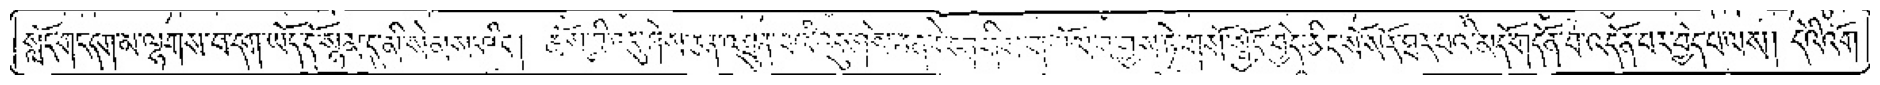

In [48]:
idx = 2894
print(images[idx])
image = cv2.imread(images[idx])
label = read_label(transcriptions[idx])

print(label)
print(len(label))
show_image(image)

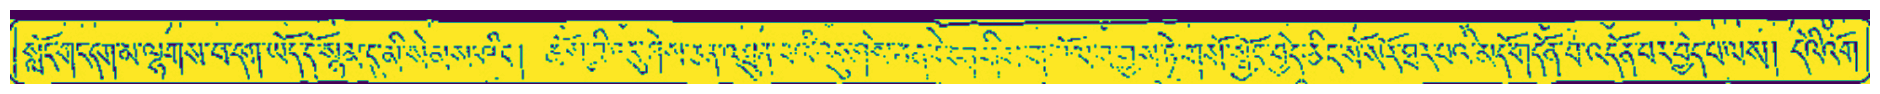

In [49]:
np_img_batch = [prepare_ocr_image2(image, target_width=ocr_inference._input_width, target_height=ocr_inference._input_height)]
            
prev_img = np_img_batch[0]
prev_img = np.transpose(np_img_batch[0], axes=[1, 2, 0])
show_image(prev_img)


In [50]:
np_img_batch = np.array(np_img_batch, np.float32)
print(np_img_batch.shape)

(1, 1, 80, 2000)


In [51]:
predicted_text, raw = ocr_inference.run(np_img_batch, replace_tsheg=" ")
pred_line = predicted_text[0]
print(pred_line)

slong gang dag ma lhags pa dag yod do snyam du mi sems shing 'i 'du shes can 'thun pa'i du shess te gsbyang byed cing gsad thar pa'i mdo gdon pa 'don par byed pa las/de'i 'og 


In [52]:
cer_score = fastwer.score_sent(pred_line, label, char_level=True)
print(cer_score /len(label))

0.0998110599078341
